# Convolution Networks

Brief historical remarks.


In the 1950s and 1960s, Hubel and Wiesel studied mammalian brains and showed that their visual cortex contain neurons that individually respond to small regions of the visual field.

https://pmc.ncbi.nlm.nih.gov/articles/PMC1363130/

Hubel and Wiesel shared the Nobel Prize in Physiology, in 1981.

In 1969, inspired by Hubel and Wiesel's work, Kunihiko Fukushima proposed a novel artificial neural network arquitecture, that in today's terminology would be referred to as a deep Convolution Network.

https://ieeexplore.ieee.org/document/4082265/authors#authors 

Convolution networks eventually became one of the main engines of the recent deep learning revolution.

In the words of Chollett, Chapter 8 of his book:  

"Computer vision is the problem domain that led to the initial rise of deep learning between 2011 and 2015. A type of deep learning model called convolutional neural networks started getting remarkably good results on image classification competitions around that time, first with Dan Ciresan winning two niche competitions (the ICDAR 2011 Chinese character recognition competition and the IJCNN 2011 German traffic signs recognition competition), and then more notably in fall 2012 with Hinton's group winning the high-profile ImageNet large-scale visual recognition challenge."

https://www.deeplearningbook.org/contents/convnets.html

# The convolution operation

**1d Convolution:** Given two 1d arrays $x=[x_1,\ldots,x_n]$ and $w = [w_1,\ldots,w_m]$ we define the convolution of $f$ with $w$ to be a new array whose entries are defined by   

$$(x*w)_k = \sum_s x_{s}w_{k-s}\;.$$

We are being purposely vague in what concerns the ranges of the indices $k$ and $s$ to simplify presentation.

**Exercise:** For the case $n=5$ and $m=3$ explore the general structure of $x*w$. Pay special attention to the "flipping" of the array $w$.

Let's see 1d convolutions in action.

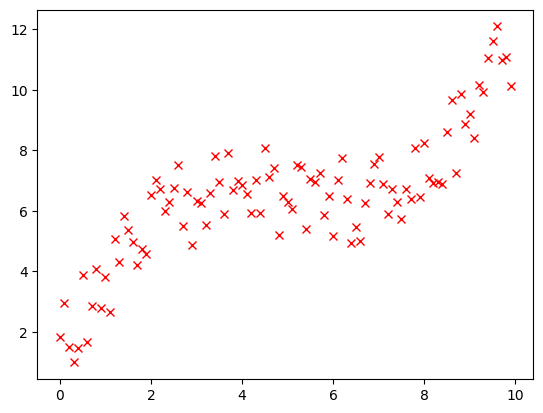

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(0,10,.1)
y = 2*np.sin(2*np.pi*x/10) + x + np.random.uniform(0,3, size=x.shape)

plt.plot(x,y,"rx")


Let's compute the moving average of the previous synthetic data.

Original shape: (100,)
Shape after convolution : (91,)


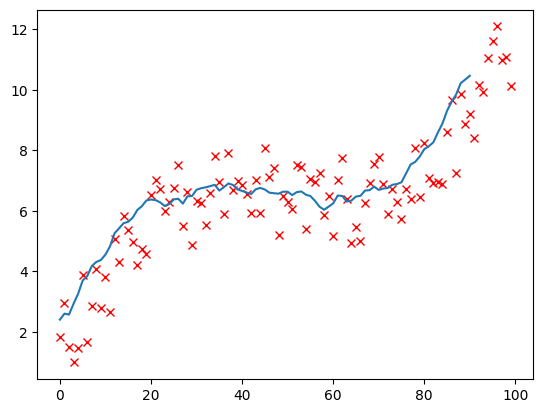

In [ ]:
#
#
n = 10
W = np.ones(n)/n
#
# Use "full", "same" and "valid" in the last input of np.convolve
#
moving_average = np.convolve(y,W,"valid")
#
print("Original shape:", y.shape)
print("Shape after convolution :",moving_average.shape)
#
plt.plot(y,'rx')
plt.plot(moving_average)

Convolution, with its "weird" flipping of one of its terms, is the "natural" mathematical operation because it's commutative and, most importantly, because of its special relation with the Fourier Transform, made clear in the Convolution Theorem

https://mathworld.wolfram.com/ConvolutionTheorem.html

In practice, in deep learning, instead of using convolution one uses the **cross-correlation** operation

$$(x\star w)_k = \sum_s x_{s}w_{s-k}\;.$$

The two operations are very similar and one can be easily computed form the other. In deep learning, the term convolution is used but, under the hood, it's a cross-correlation that's being computed.

**2d Convolution:** Given two 2d arrays $x=[x_{i,j}]$ and $w = [w_{i,j}]$ we define the convolution of $f$ with $w$ to be a new 2d array whose entries are defined by   

$$(x*w)_{n,m} = \sum_{s_1,s_2} x_{s_1,s_2}w_{n-s_1,m-s_2}\;.$$

Once again, we're being purposely vague in what concerns the ranges of the indices.

The following link leads to an instructive video
https://www.youtube.com/watch?v=KuXjwB4LzSA  

Let's see 2d convolution in action.

<ipython-input-9-bd2a047a82e8>:4: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread(image_url)


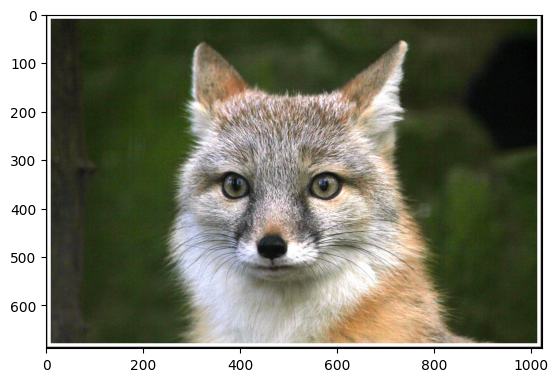

In [ ]:
import imageio

image_url = 'https://live.staticflickr.com/7492/15677707699_d9d67acf9d_b.jpg'
img = imageio.imread(image_url)

plt.imshow(img)

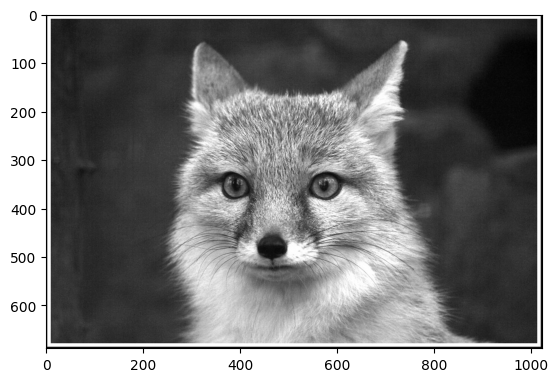

In [ ]:
def toGray(image):
  image_gr=0.2990*image[:,:,0]+0.5870*image[:,:,1]+0.1140*image[:,:,2]
  return image_gr

imgray = toGray(img)

plt.imshow(imgray,cmap='gray')

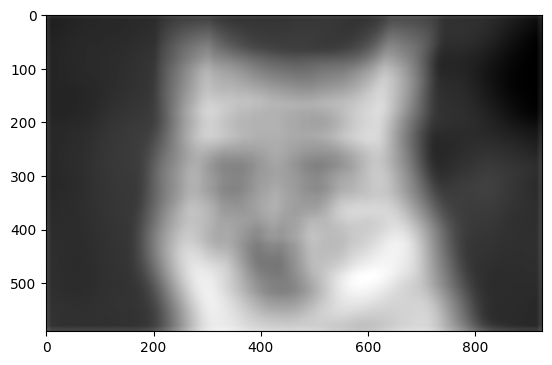

In [ ]:
from scipy import signal

n = 100
W = np.ones((n,n))/n**2

im_conv = signal.convolve2d(imgray,W,mode='valid')

plt.imshow(im_conv,cmap='gray')

A contour detector using (hard-coded) convolutions.

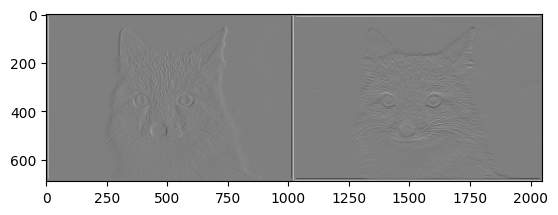

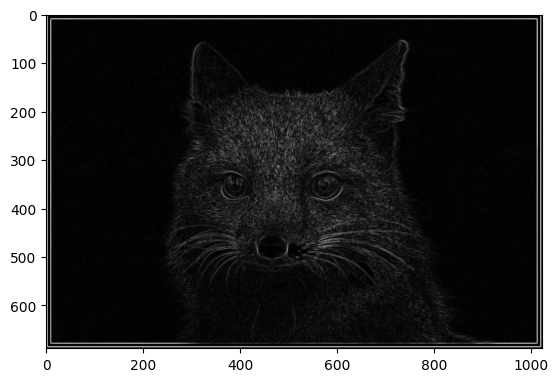

In [ ]:
Wx = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
Wy = Wx.T

gradx=signal.convolve2d(imgray,Wx,mode="same")
grady=signal.convolve2d(imgray,Wy,mode="same")

gradNorm=np.sqrt(gradx**2+grady**2)

plt.imshow(np.concatenate((gradx,grady),axis=1),cmap="gray")

plt.figure()

plt.imshow(gradNorm,cmap="gray")

**Convolution Layer:**

In deep learning, the (2d) convolution operation will be applied in the following setting:

-  We are given an input array $X\in \mathbb{R}^{B\times H\times V\times C_{in}}$ whose entry  
$$X_{b,h,v,c}$$
is the value of channel $c$, of the $b$'th batch element, in spatial position $(h,v)$.

More on the channel dimension: In the first layer of a neural network, the channel dimension typically corresponds to an intrinsic characteristic of the input, for instance, the RGB values in a polychromatic image. In a hidden layer, it will correspond to the outputs of the filters applied, in the previous layer. In the first case, $C_{in} = 3$, while in the second, $C_{in} =$ *number of filters applied in the previous layer*.

- The model will learn a tensor of weights $W\in \mathbb{R}^{f_H\times f_V\times C_{in}\times C_{out}}$ (called filters in this context) of the form
$$W_{h,v,c_{in},c_{out}}.$$

- We can also include a learnable bias vector $b\in \mathbb{R}^{C_{out}}$.

Then, an appropriate convolution/cross-correlation operation, with a bias term, becomes

$$(X*W)_{b,h,v,c_{out}} + b_{c_{out}} = \sum_{s_1,s_2,s_3} X_{b,s_1,s_2,s_3}W_{h-s_1,v-s_2,s_3,c_{out}}+b_{c_{out}}\;.$$

If we don't use any padding (see the "valid" option before) then the output of this operation has dimensions

 $$X*W + b\in \mathbb{R}^{B\times (H-f_H +1)\times (V - f_V +1)\times C_{out}}\;.$$

If needed, we can easily include padding into the operation.

A **convolution layer** is then of the form

$$\Phi(X) = \phi(X*W+b)\;,$$

where $\phi$ is an activation function acting entrywise, as always.

Let's start using these powerful layers in deep learning models.

# MNIST

The next examples follow Chapter 8 of Chollett's book closely.

In [ ]:
from tensorflow.keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

"Importantly, a convnet takes as input tensors of shape (image_height, image_width, image_channels), not including the batch dimension. In this case, we’ll configure the convnet to process inputs of size (28, 28, 1), which is the format of MNIST images."

In [ ]:
# Data normalization
# Pay special attention to the data shape.
train_images = train_images.reshape((60000, 28, 28, 1))
train_images = train_images.astype("float32") / 255
test_images = test_images.reshape((10000, 28, 28, 1))
test_images = test_images.astype("float32") / 255

np.uint8(5)

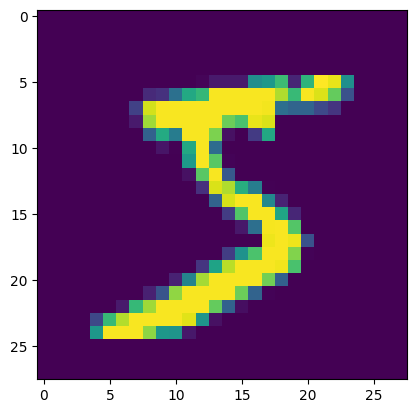

In [ ]:
plt.imshow(train_images[0])
train_labels[0]

We'll now construct a model using convolution layers.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

inputs = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(inputs)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.Flatten()(x)
outputs = layers.Dense(10, activation="softmax")(x)
model = keras.Model(inputs=inputs, outputs=outputs)

model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,202 (407.04 KB)

 Trainable params: 104,202 (407.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
3*3*32+32


320

In the constructor of Conv2D layers *layers.Conv2D(filters=32, kernel_size=3,...)*
*filters* refer to the number of filters that are going to be learned in that layer, and kernel_size = 3 means that the filters have $3\times 3$ spatial dimensions.

You might have also noticed that there are 2 types of layers that we haven't discussed yet:

 - The *flatten* layer does exactly what its name says: it takes the output of the previous layer, which has shape $(3,3,128)$, and turns it into a vector with shape $(3*3*128,)$ that can be fed to a dense layer to perform the desired classification. This is essentially what we did in the preprocessing of the MNIST data when we used a dense network to classify it.   


 - The *maxpool layer* : "(...) you may have noticed that the size of the feature maps is halved after every MaxPooling2D layer [with pool_size=2] (...) That's the role of max pooling: to aggressively downsample feature maps (...).
 Max pooling consists of extracting windows from the input feature maps and outputting the max value of each channel. It's conceptually similar to convolution, except that instead of transforming local patches via a learned linear transformation (the convolution kernel), they're transformed via a hardcoded max tensor operation."

 Some pooling strategies in deep networks were inspired by mechanisms in biological brains. Once again, we refer to Chapter 9.10 of https://www.deeplearningbook.org/contents/convnets.html.  


 **Exercise:** Turn the maxpool layers on and off and compare the number of parameters in each case.

 The model without maxpooling has other caveats:

 "It isn't conducive to learning a spatial hierarchy of features. The $3 \times 3$ windows in the third layer will only contain information coming from $7 \times 7$ windows in the initial input. The high-level patterns learned by the convnet will still be very small with regard to the initial input, which may not be enough to learn to classify digits (try recognizing a digit by only looking at it through windows that are $7\times 7$ pixels!). We need the features from the last convolution layer to contain information about the totality of the input."


 Another strategy to downsample the model and promote the mixture of information from different spatial regions and channels is the use of **strides**. In the words of Chollett:

 "The other factor that can influence output size is the notion of strides. Our description of convolution so far has assumed that the center tiles of the convolution windows are all contiguous. But the distance between two successive windows is a parameter of the convolution, called its stride, which defaults to 1. It's possible to have strided convolutions: convolutions with a stride higher than 1."

 **Exercise:** To includes strides, one just needs to use the command *strides=stride_size* in the constructor of the convnet layer. Do just that.



In [ ]:
model.compile(optimizer="rmsprop",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.fit(train_images, train_labels, epochs=5, batch_size=64,
          validation_data = (test_images,test_labels))

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8811 - loss: 0.3778 - val_accuracy: 0.9856 - val_loss: 0.0427
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9847 - loss: 0.0505 - val_accuracy: 0.9885 - val_loss: 0.0325
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9898 - loss: 0.0313 - val_accuracy: 0.9901 - val_loss: 0.0284
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9929 - loss: 0.0217 - val_accuracy: 0.9908 - val_loss: 0.0272
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9949 - loss: 0.0177 - val_accuracy: 0.9916 - val_loss: 0.0273


More insights by Chollett on ConvNets:

"Dense layers learn global patterns in their input feature space (for example, for a MNIST digit, patterns involving all pixels), whereas convolution layers learn local patterns - in the case of images, patterns found in small 2D windows of the inputs (...)"

"This key characteristic gives convnets two interesting properties:
- The patterns they learn are translation-invariant. After learning a certain pattern in the lower-right corner of a picture, a convnet can recognize it anywhere: for example, in the upper-left corner. A densely connected model would have to learn the pattern anew if it appeared at a new location. This makes convnets data-efficient when processing images (because the visual world is fundamentally translation-invariant): they need fewer training samples to learn representations that have generalization power.
- They can learn spatial hierarchies of patterns. A first convolution layer will learn small local patterns such as edges, a second convolution layer will learn larger patterns made of the features of the first layers, and so on (...). This allows convnets to efficiently learn increasingly complex and abstract visual concepts, because the visual world is fundamentally spatially hierarchical."

# Training a convnet from scratch on a small dataset

We'll now consider the example in Chapter 8.2 of Chollett's book.  

First we'll download the data from the kaggle website.
See Chapter 8.2.2 of Chollett's book for further details on how to process the download in Colab.



Training the models below will be painfully slow without a GPU. So, if possible, turn the runtime to GPU now.   

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"joolcosta","key":"0770b84de63bd38e782c78964cef7a02"}'}

In [ ]:
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle competitions download -c dogs-vs-cats

 99% 808M/812M [00:06<00:00, 193MB/s]
100% 812M/812M [00:06<00:00, 133MB/s]


Now, let's uncompress the data and organize it into appropriate folders.

In [ ]:
!unzip -qq dogs-vs-cats.zip

In [ ]:
!unzip -qq train.zip

In [ ]:
import os, shutil, pathlib

original_dir = pathlib.Path("train")
new_base_dir = pathlib.Path("cats_vs_dogs_small")

def make_subset(subset_name, start_index, end_index):
  for category in ("cat", "dog"):
      dir = new_base_dir / subset_name / category
      os.makedirs(dir)
      fnames = [f"{category}.{i}.jpg"
                for i in range(start_index, end_index)]
      for fname in fnames:
                 shutil.copyfile(src=original_dir / fname,
                                 dst=dir / fname)

make_subset("train", start_index=0, end_index=1000)
make_subset("validation", start_index=1000, end_index=1500)
make_subset("test", start_index=1500, end_index=2500)

Data preprocessing

Steps for getting it into the model are roughly as follows:

1. Read the picture files.
2. Decode the JPEG content to RGB grids of pixels.
3. Convert these into floating-point tensors.
4. Resize them to a shared size (we’ll use 180 × 180).
5. Pack them into batches (we’ll use batches of 32 images).

It may seem a bit daunting, but fortunately Keras has utilities to take care of these steps automatically. In particular, Keras features the utility function *image_dataset_from_ directory()*, which lets you quickly set up a data pipeline that can automatically turn image files on disk into batches of preprocessed tensors. This is what we'll use here."

In [ ]:
from tensorflow.keras.utils import image_dataset_from_directory

train_dataset = image_dataset_from_directory(
    new_base_dir / "train",
    image_size=(180, 180),
    batch_size=32)
validation_dataset = image_dataset_from_directory(
    new_base_dir / "validation",
    image_size=(180, 180),
    batch_size=32)
test_dataset = image_dataset_from_directory(
    new_base_dir / "test",
    image_size=(180, 180),
    batch_size=32)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.


"A *Dataset* object is an iterator: you can use it in a for loop. It will typically return batches of input data and labels. You can pass a Dataset object directly to the fit() method of a Keras model."

It has many other useful features. For more details see Chapter 8.2.4 of Chollett's book.

0
data batch shape: (32, 180, 180, 3)
labels batch shape: (32,)
tf.Tensor([0 1 0 0 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 0], shape=(32,), dtype=int32)
1
data batch shape: (32, 180, 180, 3)
labels batch shape: (32,)
tf.Tensor([0 1 0 1 0 0 0 1 1 0 0 1 0 1 0 1 1 0 0 0 1 1 0 1 1 1 1 0 0 0 1 0], shape=(32,), dtype=int32)
2
data batch shape: (32, 180, 180, 3)
labels batch shape: (32,)
tf.Tensor([1 1 1 1 1 1 0 0 0 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 1 0 1 0 1 1 0], shape=(32,), dtype=int32)


3
data batch shape: (32, 180, 180, 3)
labels batch shape: (32,)
tf.Tensor([0 0 0 1 1 1 1 0 1 1 1 0 1 0 1 0 0 1 0 0 1 1 1 1 0 1 0 0 0 0 0 0], shape=(32,), dtype=int32)


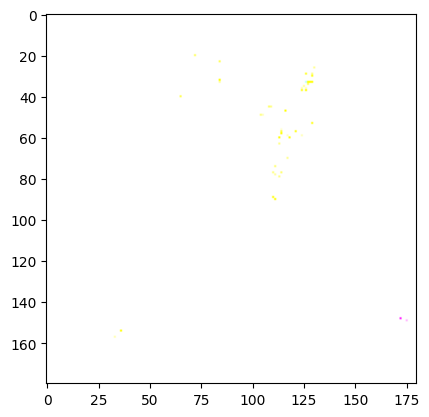

In [ ]:
import matplotlib.pyplot as plt

for i, tuple_batch in enumerate(train_dataset):
 data_batch = tuple_batch[0]
 labels_batch = tuple_batch[1]
 print(i)
 print("data batch shape:", data_batch.shape)
 print("labels batch shape:", labels_batch.shape)
 plt.imshow(data_batch[0])
 print(labels_batch)
 if i >2:
  break

Now will create a model to learn these data.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1./255)(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.Flatten()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs=inputs, outputs=outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        12,545 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 991,041 (3.78 MB)

 Trainable params: 991,041 (3.78 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(loss="binary_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])

In [ ]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
      filepath="convnet_from_scratch.keras",
      save_best_only=True,
      monitor="val_loss")
]

In [ ]:
history = model.fit(
            train_dataset,
            epochs=10,
            validation_data=validation_dataset,
            callbacks=callbacks)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 118ms/step - accuracy: 0.4949 - loss: 0.7000 - val_accuracy: 0.5000 - val_loss: 0.6929
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/step - accuracy: 0.5264 - loss: 0.6925 - val_accuracy: 0.5660 - val_loss: 0.6810
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.5856 - loss: 0.6852 - val_accuracy: 0.6480 - val_loss: 0.6497
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.6171 - loss: 0.6576 - val_accuracy: 0.5330 - val_loss: 0.8188
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 0.6438 - loss: 0.6639 - val_accuracy: 0.5690 - val_loss: 0.8308
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.6655 - loss: 0.6160 - val_accuracy: 0.6620 - val_loss: 0.6121
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.6976 - loss: 0.5864 - val_accuracy: 0.6160 - val_loss: 0.7904
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.7007 - loss: 0.5801 - val_accuracy: 0.6800 -

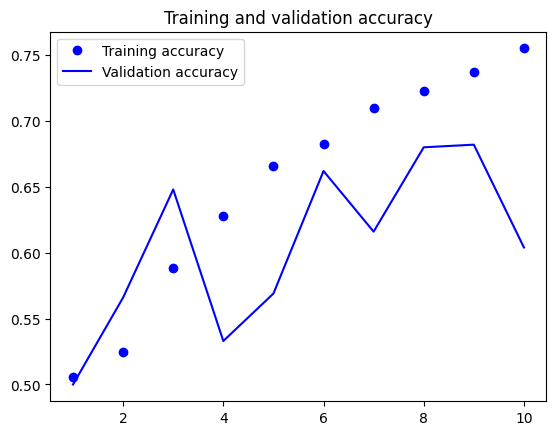

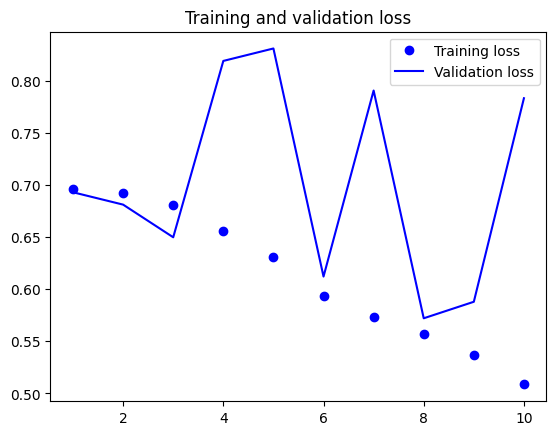

In [ ]:
import matplotlib.pyplot as plt


def history_plot(history):
  accuracy = history.history["accuracy"]
  val_accuracy = history.history["val_accuracy"]
  loss = history.history["loss"]
  val_loss = history.history["val_loss"]
  epochs = range(1, len(accuracy) + 1)
  plt.plot(epochs, accuracy, "bo", label="Training accuracy")
  plt.plot(epochs, val_accuracy, "b", label="Validation accuracy")
  plt.title("Training and validation accuracy")
  plt.legend()
  plt.figure()
  plt.plot(epochs, loss, "bo", label="Training loss")
  plt.plot(epochs, val_loss, "b", label="Validation loss")
  plt.title("Training and validation loss")
  plt.legend()

history_plot(history)

In [ ]:
model.evaluate(test_dataset)

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.6215 - loss: 0.7794


[0.804564893245697, 0.6104999780654907]

In [ ]:
# Loading and evaluationg the model saved by the callbacks
#
test_model = keras.models.load_model("convnet_from_scratch.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")


63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.7045 - loss: 0.5661
Test loss: 0.5798
Test accuracy: 0.6905


Note that running model.evaluate will give different values even if we don't change the model nor the dataset! Why is that?

# Using data augmentation

"Overfitting is caused by having too few samples to learn from, rendering you unable to train a model that can generalize to new data. (...) Data augmentation takes the approach of generating more training data from existing training samples by augmenting the samples via a number of random transformations that yield believable-looking images."

"In Keras, this can be done by adding a number of data augmentation layers at the start of your model."

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential(
  [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
  ]
)

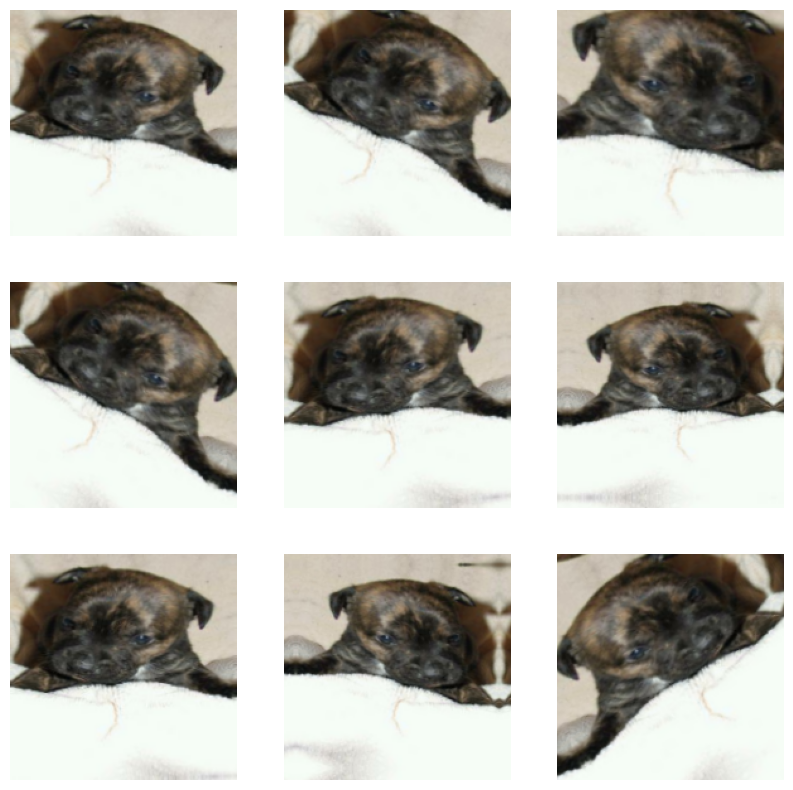

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, _ in train_dataset.take(1):
  for i in range(9):
    augmented_images = data_augmentation(images)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_images[0].numpy().astype("uint8"))
    plt.axis("off")

"If we train a new model using this data-augmentation configuration, the model will never see the same input twice. But the inputs it sees are still heavily intercorrelated because they come from a small number of original images—we can't produce new information; we can only remix existing information. As such, this may not be enough to completely get rid of overfitting. To further fight overfitting, we'll also add a Dropout layer to our model right before the densely connected classifier."

In [ ]:
inputs = keras.Input(shape=(180, 180, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1./255)(x)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.summary()

model.compile(loss="binary_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        12,545 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 991,041 (3.78 MB)

 Trainable params: 991,041 (3.78 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
            keras.callbacks.ModelCheckpoint(
            filepath="convnet_from_scratch_with_augmentation.keras",
            save_best_only=True,
            monitor="val_loss")
]

history = model.fit(
        train_dataset,
        epochs=60,
        validation_data=validation_dataset,
        callbacks=callbacks)

Epoch 1/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.5103 - loss: 0.7036 - val_accuracy: 0.5030 - val_loss: 0.6921
Epoch 2/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.5301 - loss: 0.6934 - val_accuracy: 0.5120 - val_loss: 0.6889
Epoch 3/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.5161 - loss: 0.6940 - val_accuracy: 0.5000 - val_loss: 0.7466
Epoch 4/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.5851 - loss: 0.6843 - val_accuracy: 0.5710 - val_loss: 0.6928
Epoch 5/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - accuracy: 0.6132 - loss: 0.6598 - val_accuracy: 0.5480 - val_loss: 0.6967
Epoch 6/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.6321 - loss: 0.6195 - val_accuracy: 0.6560 - val_loss: 0.6079
Epoch 7/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.6675 - loss: 0.6166 - val_accuracy: 0.6760 - val_loss: 0.6172
Epoch 8/60
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.6932 - loss: 0.5779 - val_accuracy: 0.5760 - v

KeyboardInterrupt: 

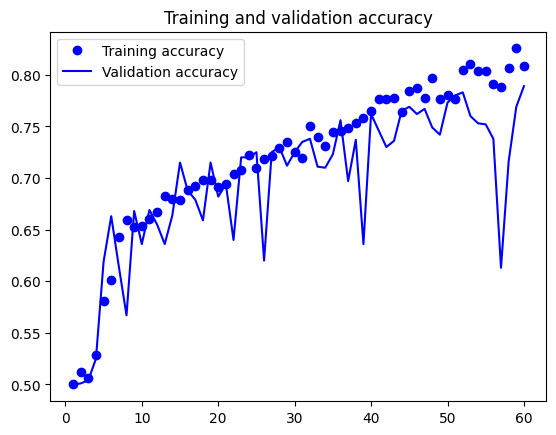

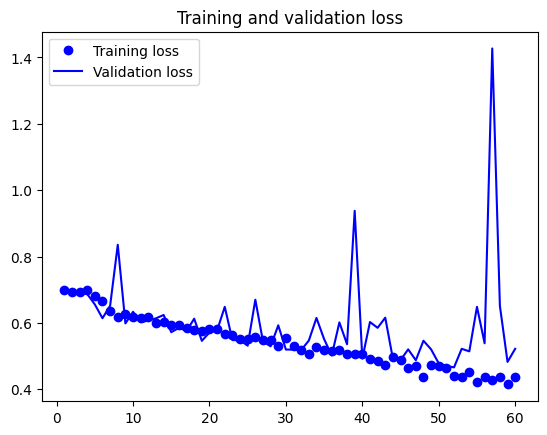

In [ ]:
history_plot(history)

In [ ]:
test_model = keras.models.load_model("convnet_from_scratch_with_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")

"By further tuning the model’s configuration (such as the number of filters per
convolution layer, or the number of layers in the model), we might be able to get an even better accuracy, likely up to 90%. But it would prove difficult to go any higher just by training our own convnet from scratch, because we have so little data to work with. As a next step to improve our accuracy on this problem, we’ll have to use a pretrained model (...)"

# Feature extraction with a pretrained model

**Pretained is the P in GPT.**  

"Feature extraction consists of using the representations learned by a previously trained model to extract interesting features from new samples. These features are then run through a new classifier, which is trained from scratch."

"Note that the level of generality (and therefore reusability) of the representations extracted by specific convolution layers depends on the depth of the layer in the model. Layers that come earlier in the model extract local, highly generic feature maps (such as visual edges, colors, and textures), whereas layers that are higher up extract more-abstract concepts (such as “cat ear” or “dog eye”)."

"So if your new dataset differs a lot from the dataset on which the original model was trained, you may be better off using only the first few layers of the model to do feature extraction, rather than using the entire convolutional base."

"Let's put this into practice by using the convolutional
base of the VGG16 network, trained on ImageNet, to extract interesting features
from cat and dog images, and then train a dogs-versus-cats classifier on top of
these features.

"The VGG16 model, among others, comes prepackaged with Keras. You can import
it from the keras.applications module."

In [ ]:
conv_base = keras.applications.vgg16.VGG16(
          weights="imagenet", # choice of pretrained weights from which to initialize the model
          include_top=False, # "False" removes the top dense classification module
          input_shape=(180, 180, 3)) # The shape of our inputs. This is optional

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 180, 180, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 180, 180, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 90, 90, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 90, 90, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 45, 45, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 45, 45, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 45, 45, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 22, 22, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 22, 22, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 22, 22, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 22, 22, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 11, 11, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 5, 5, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

**Feature Extration 1**

"We'll start by extracting features as NumPy arrays by calling the predict() method of the conv_base model on our training, validation, and testing datasets."

"(...) the VGG16 model expects
inputs that are preprocessed with the function
*keras.applications.vgg16.preprocess_input*, which scales pixel values to an appropriate range."

In [ ]:
import numpy as np

def get_features_and_labels(dataset):
  all_features = []
  all_labels = []
  for images, labels in dataset:
    preprocessed_images = keras.applications.vgg16.preprocess_input(images)  # vgg16 expects inputs with a specific structure
    features = conv_base.predict(preprocessed_images)
    all_features.append(features)
    all_labels.append(labels)
  return np.concatenate(all_features), np.concatenate(all_labels)

In [ ]:
train_features, train_labels = get_features_and_labels(train_dataset)
val_features, val_labels = get_features_and_labels(validation_dataset)
test_features, test_labels = get_features_and_labels(test_dataset)

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [ ]:
print(train_features.shape)
print(train_labels.shape)
print(val_features.shape)
print(test_features.shape)

(2000, 5, 5, 512)
(2000,)
(1000, 5, 5, 512)
(2000, 5, 5, 512)


**Exercise:** Construt an apropriate densely connected classifier, that will take as inputs the previously extracted features and has only one hidden layer with 256 units. Add also a dropout layer with .5 dropout rate.

In [ ]:
# solve here


inputs = keras.Input(shape=(5, 5, 512))
x = layers.Flatten()(inputs)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.summary()

model.compile(loss="binary_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 5, 5, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │        12,801 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,801 (50.00 KB)

 Trainable params: 12,801 (50.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

In [ ]:
callbacks = [
      keras.callbacks.ModelCheckpoint(
      filepath="feature_extraction.keras",
      save_best_only=True,
      monitor="val_loss")
]

history = model.fit(
      train_features, train_labels,
      epochs=20,
      validation_data=(val_features, val_labels),
      callbacks=callbacks)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.8807 - loss: 4.0550 - val_accuracy: 0.9760 - val_loss: 0.5795
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9659 - loss: 1.5727 - val_accuracy: 0.9770 - val_loss: 0.7709
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9802 - loss: 0.4498 - val_accuracy: 0.9690 - val_loss: 1.4901
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9913 - loss: 0.1903 - val_accuracy: 0.9720 - val_loss: 1.0397
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9925 - loss: 0.1341 - val_accuracy: 0.9800 - val_loss: 0.6604
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9954 - loss: 0.0480 - val_accuracy: 0.9720 - val_loss: 0.9447
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9958 - loss: 0.0924 - val_accuracy: 0.9740 - val_loss: 0.9880
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9891 - loss: 0.2991 - val_accuracy: 0.9660 - val_loss

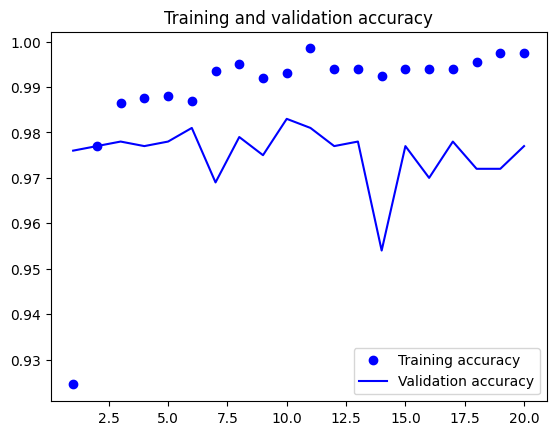

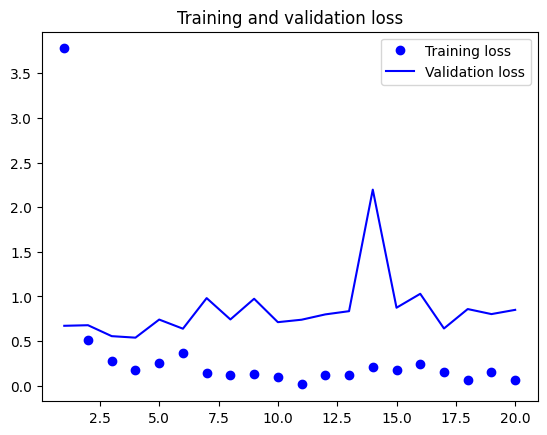

In [ ]:
history_plot(history)

**Exercise:** Evaluate the best model according to the callbacks criteria used.  

In [ ]:
# solve here


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9773 - loss: 0.6278


[0.6866140961647034, 0.9739999771118164]

"We reach a validation accuracy of about 97% — much better than we achieved in the previous section with the small model trained from scratch. This is a bit of an unfair comparison, however, because ImageNet contains many dog and cat instances, which means that our pretrained model already has the exact knowledge required for the task at hand. This won't always be the case when you use pretrained features."

**Feature Extration 2**

Another way to proceed is to use the entire model with a frozen convolutional base. This will be slower to train but will be easier to use; for instance, it will be easier to include data augmentation.

Why do we freeze the convolutional base?

"Freezing a layer or set of
layers means preventing their weights from being updated during training. If we don't
do this, the representations that were previously learned by the convolutional base will
be modified during training. Because the Dense layers on top are randomly initialized,
very large weight updates would be propagated through the network, effectively
destroying the representations previously learned."

See also the concept of Catastrophic Forgetting https://en.wikipedia.org/wiki/Catastrophic_interference

"In Keras, we freeze a layer or model by setting its trainable attribute to False."

In [ ]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False)

conv_base.trainable = False

**Exercise:** Construct a model using this base and ideas from before, including data augmentation.

In [ ]:
# Solve here

inputs = keras.Input(shape=(180, 180, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.summary()

model.compile(loss="binary_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, 180, 180,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_2        │ (None, 180, 180,  │          0 │ input_layer_13[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 180, 180)  │          0 │ sequential_2[3][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 180, 180)  │          0 │ sequential_2[3][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 180, 180)  │          0 │ sequential_2[3][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 180, 180,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 180, 180,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 5, 5, 512) │ 14,714,688 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_8 (Flatten) │ (None, 12800)     │          0 │ vgg16[2][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 12800)     │          0 │ flatten_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 1)         │     12,801 │ dropout_7[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,727,489 (56.18 MB)

 Trainable params: 12,801 (50.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

In [ ]:
callbacks = [
      keras.callbacks.ModelCheckpoint(
      filepath="feature_extraction_2.keras",
      save_best_only=True,
      monitor="val_loss")
]

history = model.fit(
    train_dataset,
    epochs=10,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 146ms/step - accuracy: 0.8097 - loss: 3.0562 - val_accuracy: 0.9700 - val_loss: 0.4810
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 144ms/step - accuracy: 0.9401 - loss: 0.9941 - val_accuracy: 0.9740 - val_loss: 0.4003
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 176ms/step - accuracy: 0.9374 - loss: 1.0450 - val_accuracy: 0.9760 - val_loss: 0.4470
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 138ms/step - accuracy: 0.9573 - loss: 0.5580 - val_accuracy: 0.9710 - val_loss: 0.5075
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 176ms/step - accuracy: 0.9554 - loss: 0.7047 - val_accuracy: 0.9790 - val_loss: 0.4754
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 137ms/step - accuracy: 0.9487 - loss: 0.7108 - val_accuracy: 0.9750 - val_loss: 0.5873
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 175ms/step - accuracy: 0.9600 - loss: 0.3847 - val_accuracy: 0.9790 - val_loss: 0.5685
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 138ms/step - accuracy: 0.9739 - loss: 0.3943 - val_accur

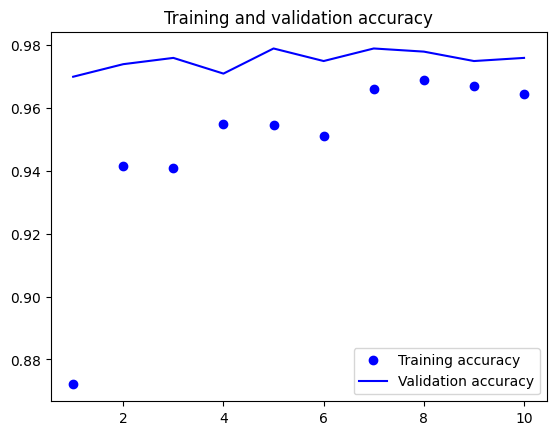

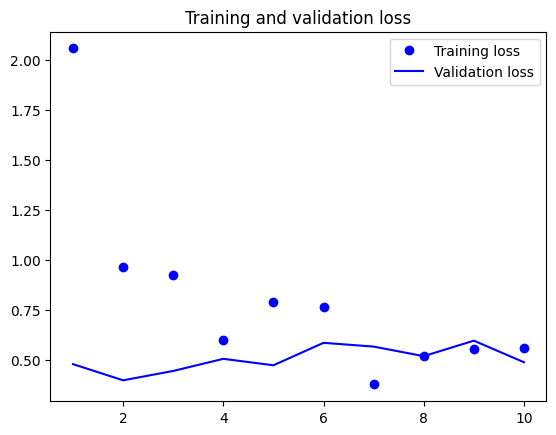

In [ ]:
history_plot(history)

In [ ]:
feature_model_2 = keras.models.load_model("feature_extraction_2.keras")
feature_model_2.evaluate(test_dataset)

63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - accuracy: 0.9639 - loss: 0.5449


[0.5545884370803833, 0.9649999737739563]

**Fine-tuning**

Let's consider yet another variation on the theme of pretraining. This one is called fine-tuning and corresponds to training only a part of the pretrained network; in this case, we will only train the final convolution block of the convolution base, typically using a small learning rate, in order not to destroy relevant pretrained features.   

In [ ]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False)

len(conv_base.layers)

19

In [ ]:
conv_base.layers

[<InputLayer name=input_layer_14, built=True>,
 <Conv2D name=block1_conv1, built=True>,
 <Conv2D name=block1_conv2, built=True>,
 <MaxPooling2D name=block1_pool, built=True>,
 <Conv2D name=block2_conv1, built=True>,
 <Conv2D name=block2_conv2, built=True>,
 <MaxPooling2D name=block2_pool, built=True>,
 <Conv2D name=block3_conv1, built=True>,
 <Conv2D name=block3_conv2, built=True>,
 <Conv2D name=block3_conv3, built=True>,
 <MaxPooling2D name=block3_pool, built=True>,
 <Conv2D name=block4_conv1, built=True>,
 <Conv2D name=block4_conv2, built=True>,
 <Conv2D name=block4_conv3, built=True>,
 <MaxPooling2D name=block4_pool, built=True>,
 <Conv2D name=block5_conv1, built=True>,
 <Conv2D name=block5_conv2, built=True>,
 <Conv2D name=block5_conv3, built=True>,
 <MaxPooling2D name=block5_pool, built=True>]

In [ ]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

**Exercise:** Disable the training of the weights of of the first 4 convolution blocks, but keep the final block trainable. Use this conv_base to construct an train a model as before.  

In [ ]:
# Solve here

conv_base.trainable = False

for i, layer in enumerate(conv_base.layers[-4:]):
  layer.trainable = True
  print(layer)

<Conv2D name=block5_conv1, built=True>
<Conv2D name=block5_conv2, built=True>
<Conv2D name=block5_conv3, built=True>
<MaxPooling2D name=block5_pool, built=True>


In [ ]:
# the model has the same structure has before,
# only now some extra parameters are trainable.
#
inputs = keras.Input(shape=(180,180,3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(256,"relu")(x)
x = layers.Dropout(.5)(x)
outputs = layers.Dense(1,"sigmoid")(x)

model = keras.Model(inputs,outputs)
model.summary()

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_15      │ (None, 180, 180,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_2        │ (None, 180, 180,  │          0 │ input_layer_15[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_6          │ (None, 180, 180)  │          0 │ sequential_2[4][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_7          │ (None, 180, 180)  │          0 │ sequential_2[4][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_8          │ (None, 180, 180)  │          0 │ sequential_2[4][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_3 (Stack)     │ (None, 180, 180,  │          0 │ get_item_6[0][0], │
│                     │ 3)                │            │ get_item_7[0][0], │
│                     │                   │            │ get_item_8[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 180, 180,  │          0 │ stack_3[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 5, 5, 512) │ 14,714,688 │ add_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_9 (Flatten) │ (None, 12800)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 256)       │  3,277,056 │ flatten_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 256)       │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 1)         │        257 │ dropout_8[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,992,001 (68.63 MB)

 Trainable params: 10,356,737 (39.51 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [ ]:
model.compile(loss="binary_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-5), # We will use a "small" learning rate
    metrics=["accuracy"])


callbacks = [
    keras.callbacks.ModelCheckpoint(
    filepath="fine_tuning.keras",
    save_best_only=True,
    monitor="val_loss")
]


In [ ]:
history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 208ms/step - accuracy: 0.5960 - loss: 5.2860 - val_accuracy: 0.9130 - val_loss: 0.4562
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 203ms/step - accuracy: 0.8170 - loss: 1.0579 - val_accuracy: 0.9410 - val_loss: 0.2802
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 172ms/step - accuracy: 0.8486 - loss: 0.7535 - val_accuracy: 0.9490 - val_loss: 0.2173
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 174ms/step - accuracy: 0.8840 - loss: 0.5127 - val_accuracy: 0.9550 - val_loss: 0.1918
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 165ms/step - accuracy: 0.9008 - loss: 0.3802 - val_accuracy: 0.9580 - val_loss: 0.1595
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 23s 203ms/step - accuracy: 0.9049 - loss: 0.3460 - val_accuracy: 0.9630 - val_loss: 0.1379
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 205ms/step - accuracy: 0.9344 - loss: 0.2237 - val_accuracy: 0.9650 - val_loss: 0.1246
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 204ms/step - accuracy: 0.9340 - loss: 0.1807 - val_accu

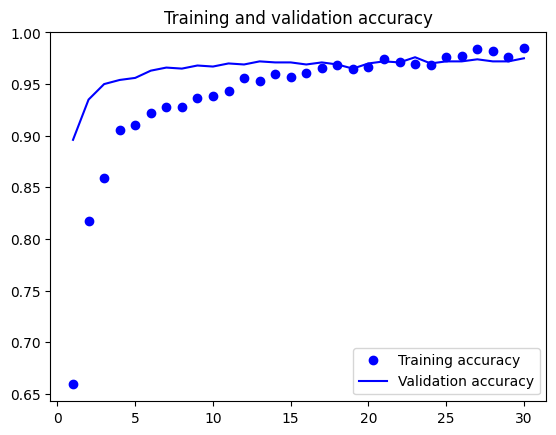

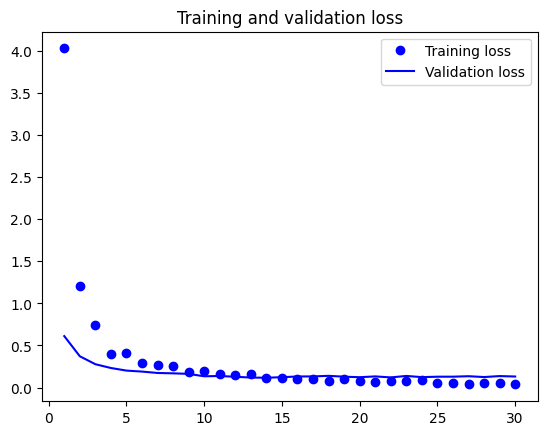

In [ ]:
history_plot(history)

In [ ]:
model_fine_tuning = keras.models.load_model("fine_tuning.keras")
model_fine_tuning.evaluate(test_dataset)

63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - accuracy: 0.9790 - loss: 0.0809


[0.08753397315740585, 0.9769999980926514]

# Worksheet #8:

Adapt the techniques developed in this notebook to the CIFAR10 dataset.  